# Task 3 – Notebook 1: channel matrix and problem formulation
8 users, 16 resource blocks (RB) of 180 kHz, cell radius 500 m, minimum distance 35 m.

**Channel** (reused from Task 1: Rayleigh gains `rayleigh_gains`): path loss $128.1+37.6\log_{10}(d/\mathrm{km})$ dB, 8 dB log-normal shadowing (one value per user), Rayleigh fading independent per user and RB.  Noise: $N_0=-174$ dBm/Hz, noise figure 9 dB, so the noise power per RB is $\sigma^2=N_0BF=-112.45$ dBm.

**Problem**

$$\max_{x_{u,n},p_n}\sum_u\sum_n x_{u,n}B\log_2(1+\gamma_{u,n}),\qquad \gamma_{u,n}=\frac{p_n g_{u,n}}{N_0BF}$$

s.t. $\sum_u x_{u,n}\le1$, $\sum_n p_n\le P_{\max}$, $R_u=\sum_n x_{u,n}B\log_2(1+\gamma_{u,n})\ge R_{\min}=1$ Mbps, $x_{u,n}\in\{0,1\}$, $p_n\ge0$.

Assumptions: powers in W; $a_{u,n}=g_{u,n}/(N_0BF)$ so $\gamma=p\,a$; every RB may be left to one user only; one drop = one channel realisation (user positions, shadowing, fading) assumed constant during the allocation. The QoS constraint can be **infeasible** (low power, far users) – this is detected and reported, never hidden.

In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd().resolve().parents[1]
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
torch.set_num_threads(1)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
from task3_resource.system import P, dbm_to_w, draw_channels, rb_rates, user_rates, POWER_DBM_GRID
from task3_resource import allocation as al, dnn, experiments as ex
T = ex.RES / "tables"; F = ex.RES / "figures"


noise power per RB: -112.45 dBm
H shape: (8, 16)


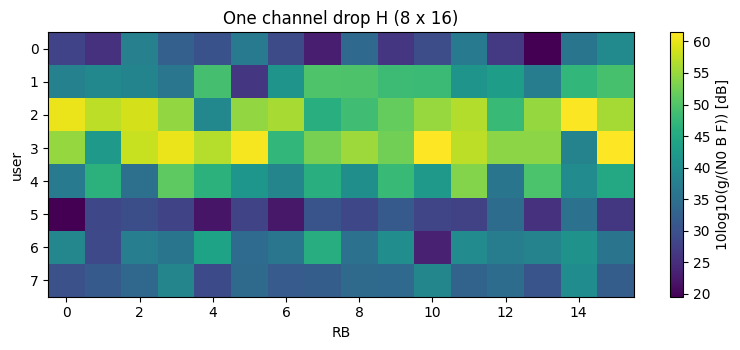

In [2]:
print("noise power per RB: %.2f dBm" % (10*np.log10(P.noise_w*1e3)))
rng = np.random.default_rng(0)
a = draw_channels(1, rng)[0]            # H: 8 users x 16 RBs (noise-normalised gain)
print("H shape:", a.shape)
fig, ax = plt.subplots(figsize=(8, 3.6))
im = ax.imshow(10*np.log10(a), aspect="auto", cmap="viridis"); plt.colorbar(im, label="10log10(g/(N0 B F)) [dB]")
ax.set_xlabel("RB"); ax.set_ylabel("user"); ax.set_title("One channel drop H (8 x 16)")
fig.tight_layout(); fig.savefig(F / "channel_matrix_example.png", dpi=150); plt.show()

### Is QoS (1 Mbps for all 8 users) achievable?  MILP feasibility over 100 drops

In [3]:
A = draw_channels(100, np.random.default_rng(1))
rows = []
for pd_ in [15, 20, 25, 30, 40]:
    feas = np.mean([al.milp_equal_power(x, dbm_to_w(pd_))[2]["qos_feasible"] for x in A])
    rows.append({"P_max [dBm]": pd_, "drops with feasible QoS (equal power) [%]": 100*feas})
pd.DataFrame(rows)

,P_max [dBm],drops with feasible QoS (equal power) [%]
0,15,8.0
1,20,38.0
2,25,70.0
3,30,95.0
4,40,99.0
